# Тепловая нагрузка здания — вариант 5
**Набор данных:** UCI Energy Efficiency (ENB2012), цель — `Y1` (нагрузка на отопление).
**Проверка модели:** целиком отложенные геометрии здания (не случайные строки).
**Исследовательский вопрос:** помогает ли регуляризация получить более устойчивую интерпретацию при взаимозависимых геометрических признаках?

## 1. Данные, физический смысл и гипотезы

**Происхождение.** Tsanas & Xifara (2012, *Energy and Buildings*, 49): 12 базовых форм здания, смоделированных в Ecotect; для каждой варьируются ориентация, площадь и распределение остекления → 12 × 64 = 768 расчётов. Это **расчётные**, а не измеренные данные, поэтому шума измерений нет, есть только «шум» от неучтённых факторов.

| Признак | Смысл | Единицы |
|---|---|---|
| `X1` | относительная компактность (отношение к самой компактной форме) | – |
| `X2` | полная площадь поверхности оболочки | м² |
| `X3` | площадь стен | м² |
| `X4` | площадь крыши (≈ площадь пола) | м² |
| `X5` | общая высота | м (3.5 или 7) |
| `X6` | ориентация: 2 – север, 3 – восток, 4 – юг, 5 – запад | категория |
| `X7` | площадь остекления как доля площади пола | – (0; 0.1; 0.25; 0.4) |
| `X8` | распределение остекления: 0 – нет, 1 – равномерно, 2…5 – N/E/S/W | категория |
| **`Y1`** | **удельная нагрузка на отопление** | кВт·ч/м² (в описании UCI единицы явно не указаны; так их трактуют по статье — стоит проверить) |

**Проверяемые физические гипотезы (сформулированы до обучения).**

* **H1.** Удельная нагрузка растёт с отношением площади оболочки к площади пола `S/F = X2/X4` (теплопотери ∝ площади оболочки, нормировка на м² пола). *Опровержение:* слабая или отрицательная корреляция `Y1` с `S/F` и отсутствие выигрыша в CV от этого признака.
* **H2.** Нагрузка растёт с долей остекления `X7` (окно теряет тепла больше стены), причём наклон зависит от геометрии (взаимодействие `X7 × S/F`). *Опровержение:* незначимый/отрицательный вклад `X7` или отсутствие выигрыша от взаимодействия.
* **H3.** Ориентация `X6` почти не влияет на нагрузку (форма в плане близка к симметричной, остекление распределяется равномерно по сторонам): различия средних по ориентациям малы по сравнению с влиянием геометрии и остекления. *Опровержение:* заметный вклад дамми-признаков `X6` и выигрыш в CV при их добавлении.

**Замечание о коллинеарности.** Из определений следует точное равенство `X2 = X3 + 2·X4` (стены + две площади «пола/крыши»), а `X5` однозначно определяется `X4`. Поэтому матрица геометрических признаков вырождена или почти вырождена — это и есть «взаимозависимые геометрические признаки» из исследовательского вопроса.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations, product

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, FunctionTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import LeaveOneGroupOut, GridSearchCV, cross_val_predict, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
SEED = 42

In [2]:
df = pd.read_excel('ENB2012_data.xlsx')      # файл лежит рядом с ноутбуком
print(df.shape, '| пропусков:', int(df.isna().sum().sum()), '| дубликатов строк:', int(df.duplicated().sum()))
df['geom'] = df.groupby(['X1', 'X2', 'X3', 'X4', 'X5']).ngroup()   # номер геометрии (12 штук)
print('строк на геометрию:', df.groupby('geom').size().unique())
print('X2 == X3 + 2*X4 для всех строк:', np.allclose(df.X2, df.X3 + 2*df.X4))
df.drop(columns=['geom']).describe().T.round(3)

(768, 10) | пропусков: 0 | дубликатов строк: 0
строк на геометрию: [64]
X2 == X3 + 2*X4 для всех строк: True


,count,mean,std,min,25%,50%,75%,max
X1,768.0,0.764,0.106,0.62,0.682,0.75,0.830,0.98
X2,768.0,671.708,88.086,514.50,606.375,673.75,741.125,808.50
X3,768.0,318.500,43.626,245.00,294.000,318.50,343.000,416.50
X4,768.0,176.604,45.166,110.25,140.875,183.75,220.500,220.50
X5,768.0,5.250,1.751,3.50,3.500,5.25,7.000,7.00
X6,768.0,3.500,1.119,2.00,2.750,3.50,4.250,5.00
X7,768.0,0.234,0.133,0.00,0.100,0.25,0.400,0.40
X8,768.0,2.812,1.551,0.00,1.750,3.00,4.000,5.00
Y1,768.0,22.307,10.090,6.01,12.992,18.95,31.668,43.10
Y2,768.0,24.588,9.513,10.90,15.620,22.08,33.132,48.03


In [3]:
geo = df.groupby('geom')[['X1', 'X2', 'X3', 'X4', 'X5']].first().join(df.groupby('geom').Y1.agg(['mean', 'min', 'max']).round(2))
geo

,X1,X2,X3,X4,X5,mean,min,max
geom,,,,,,,,
0,0.62,808.5,367.5,220.50,3.5,14.28,8.45,17.26
1,0.64,784.0,343.0,220.50,3.5,16.62,10.54,19.52
2,0.66,759.5,318.5,220.50,3.5,12.82,7.10,15.34
3,0.69,735.0,294.0,220.50,3.5,12.39,6.77,14.75
4,0.71,710.5,269.5,220.50,3.5,12.04,6.37,14.71
5,0.74,686.0,245.0,220.50,3.5,11.89,6.01,14.61
6,0.76,661.5,416.5,122.50,7.0,35.66,23.93,40.78
7,0.79,637.0,343.0,147.00,7.0,38.61,28.52,43.10
8,0.82,612.5,318.5,147.00,7.0,25.56,15.98,30.00


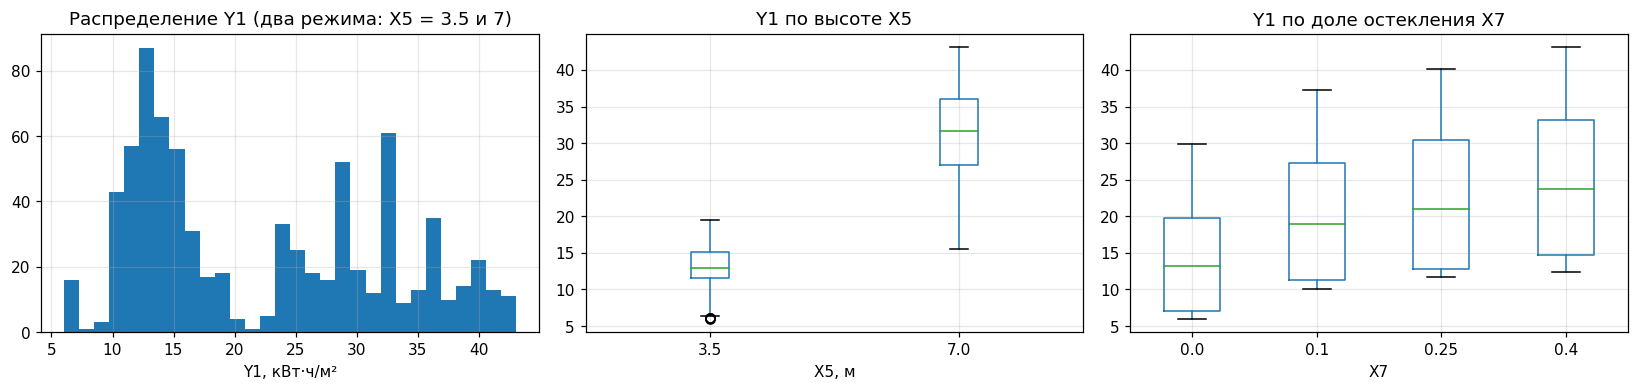

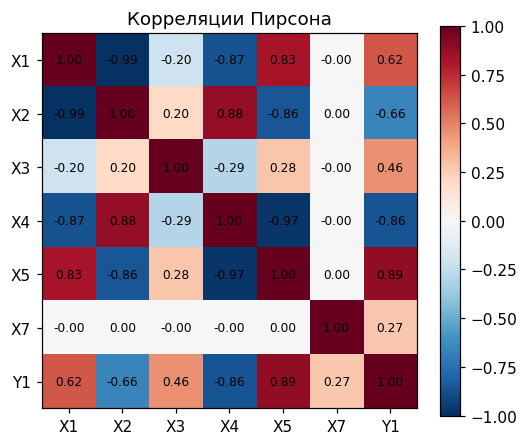

Средние Y1 по ориентации X6:
 {2: 22.31, 3: 22.38, 4: 22.26, 5: 22.28}
Средние Y1 по распределению остекления X8:
 {0: 14.29, 1: 23.03, 2: 22.93, 3: 22.68, 4: 22.89, 5: 22.68}


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(df.Y1, bins=30); ax[0].set_xlabel('Y1, кВт·ч/м²'); ax[0].set_title('Распределение Y1 (два режима: X5 = 3.5 и 7)')
df.boxplot(column='Y1', by='X5', ax=ax[1]); ax[1].set_title('Y1 по высоте X5'); ax[1].set_xlabel('X5, м'); plt.sca(ax[1]); plt.suptitle('')
df.boxplot(column='Y1', by='X7', ax=ax[2]); ax[2].set_title('Y1 по доле остекления X7'); ax[2].set_xlabel('X7'); plt.sca(ax[2]); plt.suptitle('')
plt.tight_layout(); plt.show()

num = ['X1', 'X2', 'X3', 'X4', 'X5', 'X7', 'Y1']
cm = df[num].corr()
fig, ax = plt.subplots(figsize=(5.5, 4.6)); im = ax.imshow(cm, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(num))); ax.set_xticklabels(num); ax.set_yticks(range(len(num))); ax.set_yticklabels(num); ax.grid(False)
for i, j in product(range(len(num)), repeat=2): ax.text(j, i, f'{cm.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im); ax.set_title('Корреляции Пирсона'); plt.show()
print('Средние Y1 по ориентации X6:\n', df.groupby('X6').Y1.mean().round(2).to_dict())
print('Средние Y1 по распределению остекления X8:\n', df.groupby('X8').Y1.mean().round(2).to_dict())

**Что видно до моделирования.** Геометрические признаки `X1…X5` сильно взаимосвязаны (|r| до 0.99), `X2` — точная комбинация `X3` и `X4`. Нагрузка делится на два режима по высоте. Ориентация почти не меняет среднее `Y1` (согласуется с H3), а `X8` важен лишь как «есть остекление / нет».

## 2. Разбиение данных

Случайное разбиение строк дало бы утечку: строки одной геометрии почти одинаковы по `X1…X5`. Поэтому:

* **тест** — 4 геометрии целиком (2 высоких и 2 низких, выбраны случайно с фиксированным seed **до** любого обучения);
* **обучение** — остальные 8 геометрий; настройка гиперпараметров и CV — **leave-one-geometry-out** (LOGO), т.е. каждый фолд = новая, ранее не виденная геометрия;
* тест используется один раз — для итоговой оценки.

In [5]:
rng = np.random.default_rng(SEED)
tall  = df.loc[df.X5 == 7.0, 'geom'].unique()
short = df.loc[df.X5 == 3.5, 'geom'].unique()
test_geoms = sorted(int(g) for g in list(rng.choice(tall, 2, replace=False)) + list(rng.choice(short, 2, replace=False)))
is_test = df.geom.isin(test_geoms)

feat_cols = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']
Xtr, ytr, gtr = df.loc[~is_test, feat_cols], df.loc[~is_test, 'Y1'], df.loc[~is_test, 'geom']
Xte, yte      = df.loc[is_test, feat_cols],  df.loc[is_test, 'Y1']
logo = LeaveOneGroupOut()
print('геометрии теста:', test_geoms, '| train/test строк:', len(Xtr), len(Xte))
geo.loc[test_geoms]

геометрии теста: [0, 3, 7, 11] | train/test строк: 512 256


,X1,X2,X3,X4,X5,mean,min,max
geom,,,,,,,,
0,0.62,808.5,367.5,220.50,3.5,14.28,8.45,17.26
3,0.69,735.0,294.0,220.50,3.5,12.39,6.77,14.75
7,0.79,637.0,343.0,147.00,7.0,38.61,28.52,43.10
11,0.98,514.5,294.0,110.25,7.0,27.65,15.55,32.85


## 3. Признаки и конвейеры

Всё, что «обучается» (стандартизация, кодирование, полиномы), находится **внутри** `Pipeline`, поэтому пересчитывается на каждом фолде CV.

* **RAW**: `X1…X5, X7` + one-hot для `X6`, `X8` (drop first).
* **PHYS** (физически мотивированные): `S/F = X2/X4` (H1), `X5`, `X7` (H2), взаимодействие `X7·S/F`, + one-hot `X6`, `X8`. Признак `X3/X4` не берём — он отличается от `S/F` на константу 2 (из `X2 = X3 + 2X4`), то есть дублирует его.
* Полиномиальные признаки степени 2 (степень 3 — только как проверка по CV, см. §5).
* Стандартизация применяется **после** построения полиномов ко всем столбцам — перед регуляризацией.

In [6]:
def add_phys(X):
    X = X.copy()
    X['SF']  = X['X2'] / X['X4']          # оболочка / пол, безразмерно
    X['SFG'] = X['SF'] * X['X7']          # взаимодействие геометрии с остеклением
    return X

CATS = ['X6', 'X8']
RAW_NUM  = ['X1', 'X2', 'X3', 'X4', 'X5', 'X7']
PHYS_NUM = ['SF', 'X5', 'X7', 'SFG']

def make_pipe(model, kind='raw', degree=1):
    num = RAW_NUM if kind == 'raw' else PHYS_NUM
    ct = ColumnTransformer([
        ('num', PolynomialFeatures(degree, include_bias=False), num),
        ('cat', OneHotEncoder(drop='first'), CATS)])
    steps = [('phys', FunctionTransformer(add_phys))] if kind == 'phys' else []
    return Pipeline(steps + [('ct', ct), ('sc', StandardScaler()), ('m', model)])

def metrics(y, p):
    return dict(MAE=mean_absolute_error(y, p), RMSE=mean_squared_error(y, p) ** .5, R2=r2_score(y, p))

## 4. Модели и подбор гиперпараметров

Гиперпараметры (α, `l1_ratio`, степень в §5) выбираются **только** по LOGO-CV на обучающих геометриях. CV-метрики ниже — по объединённым out-of-fold предсказаниям; они слегка оптимистичны, потому что те же фолды использовались для выбора α (вложенную CV не делаем ради скорости).

In [7]:
alphas = np.logspace(-3, 3, 13)
specs = {   # имя: (конвейер, сетка)
 '0. Среднее (базовая)':        (Pipeline([('m', DummyRegressor())]), None),
 '1. МНК, RAW линейная':        (make_pipe(LinearRegression(), 'raw', 1), None),
 '2. МНК, PHYS линейная':       (make_pipe(LinearRegression(), 'phys', 1), None),
 '3. МНК, RAW полином-2':       (make_pipe(LinearRegression(), 'raw', 2), None),
 '4. МНК, PHYS полином-2':      (make_pipe(LinearRegression(), 'phys', 2), None),
 '5. Ridge, RAW линейная':      (make_pipe(Ridge(), 'raw', 1),  {'m__alpha': alphas}),
 '6. Ridge, RAW полином-2':     (make_pipe(Ridge(), 'raw', 2),  {'m__alpha': alphas}),
 '7. Ridge, PHYS полином-2':    (make_pipe(Ridge(), 'phys', 2), {'m__alpha': alphas}),
 '8. Lasso, RAW полином-2':     (make_pipe(Lasso(max_iter=100000), 'raw', 2), {'m__alpha': np.logspace(-4, 0, 9)}),
 '9. ElasticNet, RAW полином-2':(make_pipe(ElasticNet(max_iter=100000), 'raw', 2),
                                 {'m__alpha': np.logspace(-4, 0, 9), 'm__l1_ratio': [.2, .5, .8]}),
}
fitted, rows, oof_preds = {}, [], {}
for name, (pipe, grid) in specs.items():
    if grid:
        gs = GridSearchCV(pipe, grid, cv=logo, scoring='neg_root_mean_squared_error', n_jobs=-1).fit(Xtr, ytr, groups=gtr)
        best, params = gs.best_estimator_, {k.split('__')[1]: round(float(v), 4) for k, v in gs.best_params_.items()}
    else:
        best, params = pipe.fit(Xtr, ytr), {}
    oof = cross_val_predict(best, Xtr, ytr, cv=logo, groups=gtr)
    best.fit(Xtr, ytr); fitted[name] = best; oof_preds[name] = oof
    r = {'модель': name, 'гиперпарам.': params}
    for tag, (yy, pp) in {'train': (ytr, best.predict(Xtr)), 'CV': (ytr, oof), 'test': (yte, best.predict(Xte))}.items():
        for k, v in metrics(yy, pp).items(): r[f'{k} {tag}'] = round(v, 3)
    rows.append(r)
res = pd.DataFrame(rows).set_index('модель')
res

,гиперпарам.,MAE train,RMSE train,R2 train,MAE CV,RMSE CV,R2 CV,MAE test,RMSE test,R2 test
модель,,,,,,,,,,
0. Среднее (базовая),{},8.642,9.496,0.000,9.818000e+00,1.072500e+01,-2.760000e-01,1.009200e+01,1.119600e+01,-1.600000e-02
"1. МНК, RAW линейная",{},1.221,1.498,0.975,4.763000e+00,6.243000e+00,5.680000e-01,5.565000e+00,6.682000e+00,6.380000e-01
"2. МНК, PHYS линейная",{},1.233,1.480,0.976,1.972000e+00,2.323000e+00,9.400000e-01,3.862000e+00,5.236000e+00,7.780000e-01
"3. МНК, RAW полином-2",{},0.422,0.582,0.996,8.019187e+11,1.492122e+12,-2.469175e+22,2.197992e+12,2.469425e+12,-4.940925e+22
"4. МНК, PHYS полином-2",{},1.153,1.400,0.978,1.070500e+01,2.122300e+01,-3.995000e+00,4.015000e+00,5.290000e+00,7.730000e-01
"5. Ridge, RAW линейная",{'alpha': 31.6228},1.318,1.623,0.971,1.953000e+00,2.311000e+00,9.410000e-01,4.582000e+00,5.847000e+00,7.230000e-01
"6. Ridge, RAW полином-2",{'alpha': 10.0},0.614,0.794,0.993,1.462000e+00,1.707000e+00,9.680000e-01,4.613000e+00,5.525000e+00,7.530000e-01
"7. Ridge, PHYS полином-2",{'alpha': 3.1623},1.223,1.477,0.976,2.123000e+00,2.453000e+00,9.330000e-01,3.807000e+00,5.229000e+00,7.780000e-01
"8. Lasso, RAW полином-2",{'alpha': 0.0316},0.631,0.822,0.993,1.494000e+00,1.785000e+00,9.650000e-01,4.820000e+00,5.564000e+00,7.490000e-01


In [8]:
cols = ['MAE train', 'MAE CV', 'MAE test', 'RMSE train', 'RMSE CV', 'RMSE test', 'R2 train', 'R2 CV', 'R2 test']
res[cols].style.format('{:.2f}').background_gradient(subset=['RMSE test'], cmap='RdYlGn_r')

,MAE train,MAE CV,MAE test,RMSE train,RMSE CV,RMSE test,R2 train,R2 CV,R2 test
модель,,,,,,,,,
0. Среднее (базовая),8.64,9.82,10.09,9.50,10.72,11.20,0.00,-0.28,-0.02
"1. МНК, RAW линейная",1.22,4.76,5.57,1.50,6.24,6.68,0.97,0.57,0.64
"2. МНК, PHYS линейная",1.23,1.97,3.86,1.48,2.32,5.24,0.98,0.94,0.78
"3. МНК, RAW полином-2",0.42,801918712898.72,2197991634776.50,0.58,1492121523408.64,2469425211253.38,1.00,-24691745566975124832256.00,-49409246465078652305408.00
"4. МНК, PHYS полином-2",1.15,10.71,4.01,1.40,21.22,5.29,0.98,-4.00,0.77
"5. Ridge, RAW линейная",1.32,1.95,4.58,1.62,2.31,5.85,0.97,0.94,0.72
"6. Ridge, RAW полином-2",0.61,1.46,4.61,0.79,1.71,5.53,0.99,0.97,0.75
"7. Ridge, PHYS полином-2",1.22,2.12,3.81,1.48,2.45,5.23,0.98,0.93,0.78
"8. Lasso, RAW полином-2",0.63,1.49,4.82,0.82,1.78,5.56,0.99,0.96,0.75


## 5. Сложность модели, регуляризация и переобучение

Ошибка по сложности: (а) степень полинома 1/2/3 для МНК и Ridge; (б) сила регуляризации α. Степень 3 допускается только при подтверждённом улучшении по CV.

In [10]:
def loo_rmse(pipe):
    oof = cross_val_predict(pipe, Xtr, ytr, cv=logo, groups=gtr)
    return mean_squared_error(ytr, oof) ** .5

deg_rows = []
for d in [1, 2, 3]:
    ols = make_pipe(LinearRegression(), 'raw', d)
    ridge = GridSearchCV(make_pipe(Ridge(), 'raw', d), {'m__alpha': alphas}, cv=logo,
                         scoring='neg_root_mean_squared_error', n_jobs=-1).fit(Xtr, ytr, groups=gtr)
    nfeat = ols.fit(Xtr, ytr)[:-1].transform(Xtr).shape[1]
    deg_rows.append(dict(степень=d, признаков=nfeat, **{'МНК: RMSE train': mean_squared_error(ytr, ols.predict(Xtr))**.5,
        'МНК: RMSE CV': loo_rmse(make_pipe(LinearRegression(), 'raw', d)),
        'Ridge: RMSE CV': loo_rmse(ridge.best_estimator_), 'Ridge α': ridge.best_params_['m__alpha']}))
pd.DataFrame(deg_rows).round(2).set_index('степень')

,признаков,МНК: RMSE train,МНК: RMSE CV,Ridge: RMSE CV,Ridge α
степень,,,,,
1,14,1.50,6.240000e+00,2.31,31.62
2,35,0.58,1.492122e+12,1.71,10.00
3,91,0.49,3.128349e+11,2.14,100.00


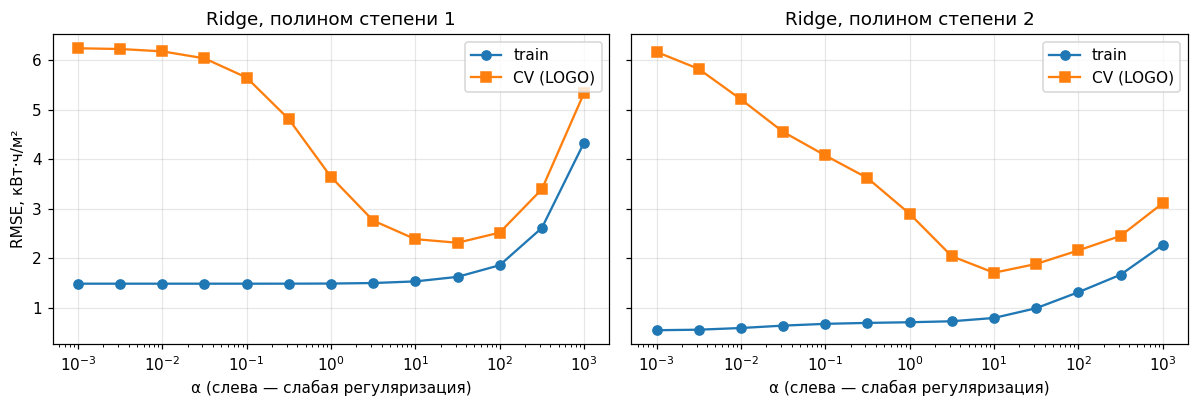

In [11]:
curves = {}
for d in [1, 2]:
    tr_, cv_ = [], []
    for a in alphas:
        p = make_pipe(Ridge(alpha=a), 'raw', d)
        tr_.append(mean_squared_error(ytr, p.fit(Xtr, ytr).predict(Xtr)) ** .5); cv_.append(loo_rmse(make_pipe(Ridge(alpha=a), 'raw', d)))
    curves[d] = (tr_, cv_)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a_, d in zip(ax, [1, 2]):
    a_.semilogx(alphas, curves[d][0], 'o-', label='train'); a_.semilogx(alphas, curves[d][1], 's-', label='CV (LOGO)')
    a_.set_title(f'Ridge, полином степени {d}'); a_.set_xlabel('α (слева — слабая регуляризация)'); a_.legend()
ax[0].set_ylabel('RMSE, кВт·ч/м²'); plt.tight_layout(); plt.show()

**Как читать.** При малых α (особенно для полинома 2) ошибка на обучении мала, а в CV заметно выше — **переобучение** (параметров много, а различных геометрий всего 8). Слишком большие α поднимают обе ошибки — **недообучение**. Минимум CV — компромисс. Если степень 3 не даёт заметного выигрыша по CV, остаёмся на степени ≤ 2 (см. таблицу выше).

## 6. Измеренное — предсказанное и остатки (тест)

Берём лучшую по **CV** (не по тесту!) регуляризованную модель.

Лучшая по CV среди регуляризованных: 6. Ridge, RAW полином-2 {'alpha': 10.0}


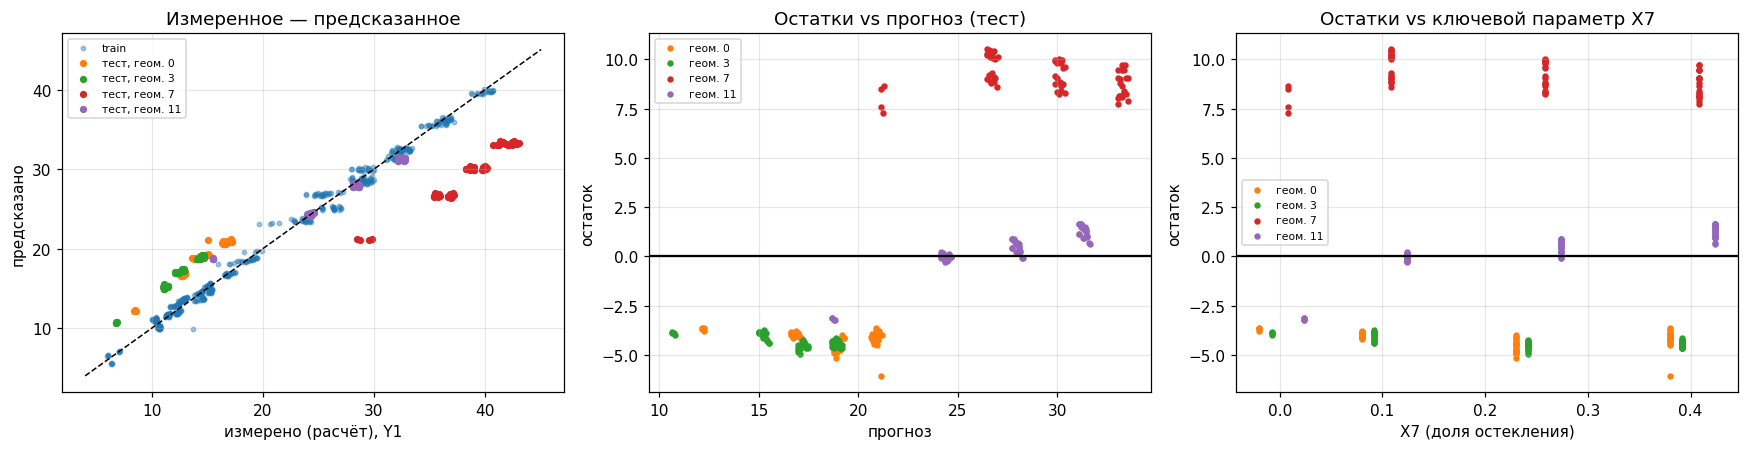

Средний остаток по геометриям теста (смещение):
{0: -4.2, 3: -4.31, 7: 9.15, 11: 0.35}
Корреляция остатка с прогнозом: 0.80, с X7: 0.02


In [13]:
reg_names = [n for n in res.index if any(k in n for k in ['Ridge', 'Lasso', 'ElasticNet'])]
best_name = res.loc[reg_names, 'RMSE CV'].idxmin()
best = fitted[best_name]; print('Лучшая по CV среди регуляризованных:', best_name, res.loc[best_name, 'гиперпарам.'])
pte = best.predict(Xte); ptr = best.predict(Xtr); res_te = yte - pte

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
lim = [df.Y1.min() - 2, df.Y1.max() + 2]
col = {g: f'C{i + 1}' for i, g in enumerate(test_geoms)}
ax[0].plot(lim, lim, 'k--', lw=1); ax[0].scatter(ytr, ptr, s=8, alpha=.4, label='train')
for g in test_geoms: m = (df.loc[is_test, 'geom'] == g).values; ax[0].scatter(yte[m], pte[m], s=14, c=col[g], label=f'тест, геом. {g}')
ax[0].set_xlabel('измерено (расчёт), Y1'); ax[0].set_ylabel('предсказано'); ax[0].set_title('Измеренное — предсказанное'); ax[0].legend(fontsize=7)
[ax[1].scatter(pte[(df.loc[is_test, 'geom'] == g).values], res_te[(df.loc[is_test, 'geom'] == g).values], s=10, c=col[g], label=f'геом. {g}') for g in test_geoms]; ax[1].legend(fontsize=7); ax[1].axhline(0, c='k'); ax[1].set_xlabel('прогноз'); ax[1].set_ylabel('остаток'); ax[1].set_title('Остатки vs прогноз (тест)')
for g in test_geoms: m = (df.loc[is_test, 'geom'] == g).values; ax[2].scatter(Xte.X7[m] + (g - 5) * .004, res_te[m], s=10, c=col[g], label=f'геом. {g}')
ax[2].axhline(0, c='k'); ax[2].set_xlabel('X7 (доля остекления)'); ax[2].set_ylabel('остаток'); ax[2].set_title('Остатки vs ключевой параметр X7'); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

print('Средний остаток по геометриям теста (смещение):'); print(res_te.groupby(df.loc[is_test, 'geom']).mean().round(2).to_dict())
print('Корреляция остатка с прогнозом: %.2f, с X7: %.2f' % (np.corrcoef(pte, res_te)[0, 1], np.corrcoef(Xte.X7, res_te)[0, 1]))

**Что проверяем в остатках.** Если остатки сгруппированы по геометриям (у каждой своё ненулевое среднее), значит модель систематически ошибается на новой форме здания — это ошибка *переноса на новую геометрию*, а не случайный шум. Сравните знак/величину смещения со средним `Y1` каждой геометрии.

## 7. Проверка на отложенном режиме и «обычная» интерполяция

Сравниваем три оценки качества одной и той же модели (Ridge, RAW, полином-2 с α из CV):

1. **случайная** KFold-CV по строкам (интерполяция — геометрии «видны» модели);
2. **групповая** LOGO-CV на обучающих геометриях;
3. **тест на отложенных геометриях**.

Затем — устойчивость вывода к выбору отложенных геометрий: все 15×15 = 225 способов отложить 2 высокие + 2 низкие геометрии, α подбирается внутри каждого разбиения по LOGO.

In [14]:
alpha6 = res.loc['6. Ridge, RAW полином-2', 'гиперпарам.']['alpha']
mk = lambda: make_pipe(Ridge(alpha=alpha6), 'raw', 2)
Xall, yall = df[feat_cols], df.Y1
rand_oof = cross_val_predict(mk(), Xall, yall, cv=KFold(5, shuffle=True, random_state=SEED))
cmp = pd.DataFrame({'оценка': ['случайная KFold-CV (все данные)', 'групповая LOGO-CV (train)', 'тест, отложенные геометрии'],
                    'RMSE': [mean_squared_error(yall, rand_oof) ** .5, res.loc['6. Ridge, RAW полином-2', 'RMSE CV'], res.loc['6. Ridge, RAW полином-2', 'RMSE test']]}).round(2)
cmp

,оценка,RMSE
0,случайная KFold-CV (все данные),2.58
1,групповая LOGO-CV (train),1.71
2,"тест, отложенные геометрии",5.52


                  mean   min   25%    50%    75%    max
модель                                                 
Ridge RAW лин.    4.57  1.49  3.58   4.47   5.83   8.89
Ridge RAW пол-2   5.24  1.40  2.49   4.49   5.84  34.23
МНК RAW лин.      5.85  1.44  4.51   5.44   7.32  16.99
Среднее          10.12  6.75  8.99  10.19  11.20  13.42


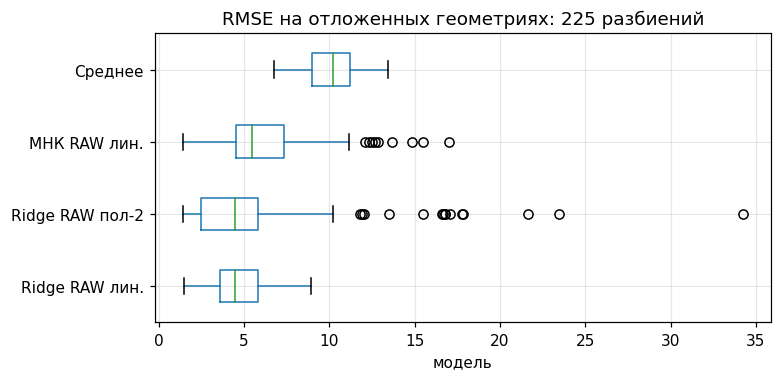

In [15]:
from sklearn.linear_model import RidgeCV
pairs_t, pairs_s = list(combinations(tall, 2)), list(combinations(short, 2))
out = []
for pt, ps in product(pairs_t, pairs_s):
    te_m = df.geom.isin(list(pt) + list(ps)).values
    Xa, ya, ga = df.loc[~te_m, feat_cols], df.Y1[~te_m], df.geom[~te_m]
    cvsplit = list(LeaveOneGroupOut().split(Xa, ya, ga))
    for nm, kind, d in [('Ridge RAW пол-2', 'raw', 2), ('Ridge RAW лин.', 'raw', 1)]:
        p = make_pipe(RidgeCV(alphas=alphas, cv=cvsplit, scoring='neg_root_mean_squared_error'), kind, d).fit(Xa, ya)
        out.append((nm, mean_squared_error(df.Y1[te_m], p.predict(df.loc[te_m, feat_cols])) ** .5))
    o = LinearRegression(); p = make_pipe(o, 'raw', 1).fit(Xa, ya)
    out.append(('МНК RAW лин.', mean_squared_error(df.Y1[te_m], p.predict(df.loc[te_m, feat_cols])) ** .5))
    out.append(('Среднее', mean_squared_error(df.Y1[te_m], np.full(te_m.sum(), ya.mean())) ** .5))
sens = pd.DataFrame(out, columns=['модель', 'RMSE test'])
print(sens.groupby('модель')['RMSE test'].describe()[['mean', 'min', '25%', '50%', '75%', 'max']].round(2))
fig, ax = plt.subplots(figsize=(7, 3.5)); sens.boxplot(column='RMSE test', by='модель', ax=ax, vert=False); plt.suptitle(''); ax.set_title('RMSE на отложенных геометриях: 225 разбиений'); plt.show()

**Вывод по §7.** Если случайная CV заметно оптимистичнее групповой и теста — обычная интерполяционная оценка завышает качество: модель хорошо интерполирует между уже виденными геометриями, но хуже переносится на новые. Разброс по 225 разбиениям показывает, насколько результат одного теста зависит от того, какие именно формы отложены (крайние геометрии — экстраполяция).

## 8. Исследовательский вопрос: устойчивость коэффициентов

Сравниваем МНК, Ridge, Lasso, Elastic Net на **линейной RAW-модели** (чтобы коэффициенты интерпретировались напрямую; признаки стандартизованы, поэтому величины сопоставимы). Гиперпараметры берём из LOGO-CV (Ridge) и фиксируем для бутстрэпа. Затем:

* число обусловленности матрицы геометрических признаков;
* **бутстрэп по строкам** (B = 300): знак, разброс и коэффициент вариации;
* **leave-one-geometry-out**: как меняются коэффициенты, если убрать одну геометрию (чувствительность к коррелированным признакам).

In [16]:
G = StandardScaler().fit_transform(Xtr[['X1', 'X2', 'X3', 'X4', 'X5']])
sv = np.linalg.svd(G, compute_uv=False)
print('Сингулярные числа геометрических признаков (стандартизованных):', sv.round(4))
print('ранг (tol=1e-8):', np.linalg.matrix_rank(G, tol=1e-8), 'из 5; число обусловленности κ2 =', f'{sv[0] / max(sv[-1], 1e-300):.3g}')

Сингулярные числа геометрических признаков (стандартизованных): [43.8083 24.9914  3.7311  1.5312  0.    ]
ранг (tol=1e-8): 4 из 5; число обусловленности κ2 = 1.58e+16


In [17]:
lin_models = {
 'МНК':   make_pipe(LinearRegression(), 'raw', 1),
 'Ridge': make_pipe(Ridge(alpha=res.loc['5. Ridge, RAW линейная', 'гиперпарам.']['alpha']), 'raw', 1),
}
for nm, est in [('Lasso', Lasso(max_iter=100000)), ('ElasticNet', ElasticNet(max_iter=100000))]:
    grid = {'m__alpha': np.logspace(-3, 0, 7)} if nm == 'Lasso' else {'m__alpha': np.logspace(-3, 0, 7), 'm__l1_ratio': [.2, .5, .8]}
    gs = GridSearchCV(make_pipe(est, 'raw', 1), grid, cv=logo, scoring='neg_root_mean_squared_error', n_jobs=-1).fit(Xtr, ytr, groups=gtr)
    lin_models[nm] = gs.best_estimator_; print(nm, 'лучшие параметры:', gs.best_params_)
for m in lin_models.values(): m.fit(Xtr, ytr)
names = lin_models['МНК'][:-1].get_feature_names_out() if hasattr(lin_models['МНК'][:-1], 'get_feature_names_out') else None
names = [n.split('__')[1] for n in names]
coef = pd.DataFrame({k: m['m'].coef_ for k, m in lin_models.items()}, index=names).round(3)
coef

Lasso лучшие параметры: {'m__alpha': 0.31622776601683794}
ElasticNet лучшие параметры: {'m__alpha': 0.1, 'm__l1_ratio': 0.2}


,МНК,Ridge,Lasso,ElasticNet
X1,5.448000e+00,1.590,0.000,1.459
X2,-2.278212e+14,-1.051,-0.000,-1.031
X3,1.472817e+14,3.498,1.563,3.362
X4,2.676982e+14,-2.819,-7.660,-2.825
X5,9.890000e-01,1.815,0.000,1.936
X7,2.228000e+00,2.282,2.361,2.286
X6_3,-1.800000e-02,0.014,0.000,0.012
X6_4,0.000000e+00,-0.040,-0.000,-0.013
X6_5,-3.700000e-02,-0.037,-0.000,-0.010
X8_1,1.750000e+00,0.991,0.000,0.756


In [18]:
B = 300; rs = np.random.default_rng(SEED); n = len(Xtr)
boot = {k: np.zeros((B, len(names))) for k in lin_models}
from sklearn.base import clone
for b in range(B):
    idx = rs.integers(0, n, n)
    for k, m in lin_models.items():
        boot[k][b] = clone(m).fit(Xtr.iloc[idx], ytr.iloc[idx])['m'].coef_
base = {k: m['m'].coef_ for k, m in lin_models.items()}
summ = []
for k in lin_models:
    sd = boot[k].std(0); sign_ok = (np.sign(boot[k]) == np.sign(base[k])).mean(0)
    for j, nme in enumerate(names):
        summ.append(dict(модель=k, признак=nme, коэф=base[k][j], sd=sd[j], **{'доля тот же знак': sign_ok[j]}))
S = pd.DataFrame(summ)
key = ['X1', 'X2', 'X3', 'X4', 'X5', 'X7']
print('Бутстрэп: среднее sd по коррелированным геометрическим коэффициентам X1…X5:')
print(S[S.признак.isin(['X1', 'X2', 'X3', 'X4', 'X5'])].groupby('модель').sd.mean().round(3).to_dict())
S[S.признак.isin(key)].pivot(index='признак', columns='модель', values=['коэф', 'sd', 'доля тот же знак']).round(2)

Бутстрэп: среднее sd по коррелированным геометрическим коэффициентам X1…X5:
{'ElasticNet': 0.085, 'Lasso': 0.075, 'Ridge': 0.092, 'МНК': 8569276463868.822}


коэф                                   sd              \
модель  ElasticNet Lasso Ridge           МНК ElasticNet Lasso Ridge   
признак                                                               
X1            1.46  0.00  1.59  5.450000e+00       0.08  0.00  0.09   
X2           -1.03 -0.00 -1.05 -2.278212e+14       0.05  0.00  0.05   
X3            3.36  1.56  3.50  1.472817e+14       0.10  0.11  0.11   
X4           -2.83 -7.66 -2.82  2.676982e+14       0.07  0.16  0.07   
X5            1.94  0.00  1.82  9.900000e-01       0.12  0.10  0.13   
X7            2.29  2.36  2.28  2.230000e+00       0.09  0.13  0.09   

                      доля тот же знак                    
модель            МНК       ElasticNet Lasso Ridge   МНК  
признак                                                   
X1       6.500000e-01              1.0  1.00   1.0  1.00  
X2       1.528049e+13              1.0  1.00   1.0  0.06  
X3       9.787581e+12              1.0  1.00   1.0  0.99  
X4       1.777831e+13              1.0  1.00   1.0  0.01  
X5       3.900000e-01              1.0  0.84   1.0  0.98  
X7       9.000000e-02              1.0  1.00   1.0  1.00

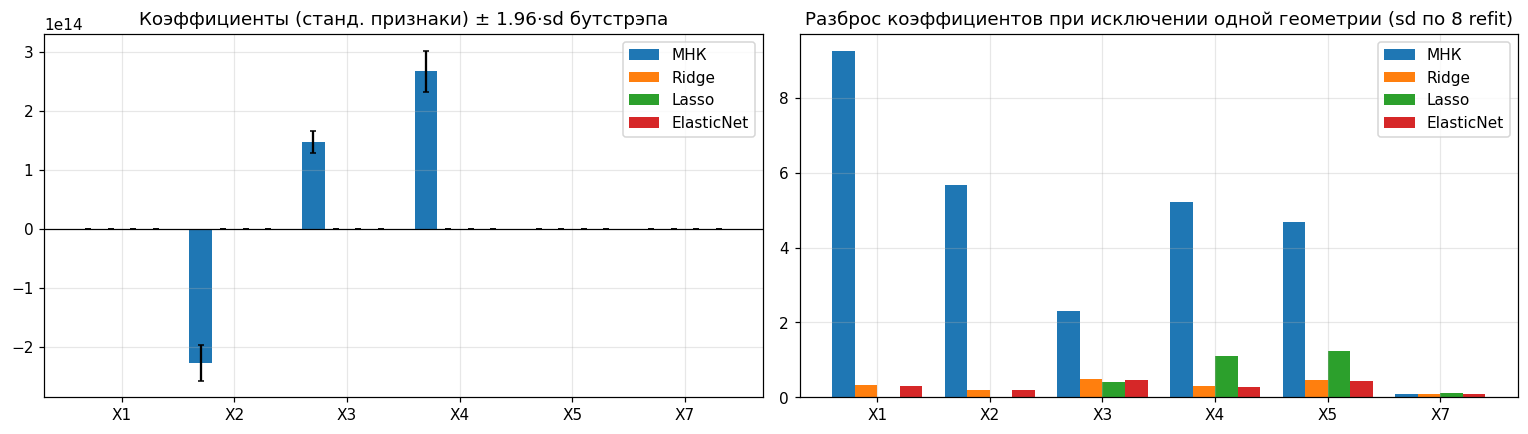

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
pos = np.arange(len(key)); w = .2
for i, k in enumerate(lin_models):
    sub = S[(S.модель == k) & S.признак.isin(key)].set_index('признак').loc[key]
    ax[0].bar(pos + i * w, sub['коэф'], w, yerr=1.96 * sub['sd'], capsize=2, label=k)
ax[0].set_xticks(pos + 1.5 * w); ax[0].set_xticklabels(key); ax[0].axhline(0, c='k', lw=.8)
ax[0].set_title('Коэффициенты (станд. признаки) ± 1.96·sd бутстрэпа'); ax[0].legend()

geoms_tr = sorted(gtr.unique()); lo = {k: [] for k in lin_models}
for g in geoms_tr:
    m = (gtr != g).values
    for k, mdl in lin_models.items(): lo[k].append(clone(mdl).fit(Xtr[m], ytr[m])['m'].coef_[[names.index(c) for c in key]])
for i, k in enumerate(lin_models):
    ax[1].bar(pos + i * w, np.std(lo[k], axis=0), w, label=k)
ax[1].set_xticks(pos + 1.5 * w); ax[1].set_xticklabels(key); ax[1].set_title('Разброс коэффициентов при исключении одной геометрии (sd по 8 refit)'); ax[1].legend()
plt.tight_layout(); plt.show()

**Как интерпретировать.**
* Для МНК коэффициенты коррелированных `X1…X5` могут быть большими, противоположных знаков и неустойчивыми (при точной коллинеарности `X2 = X3 + 2X4` решение неединственно; `sklearn` выбирает минимальную норму). Ridge «делит» вес между коррелированными признаками и уменьшает дисперсию; Lasso/Elastic Net зануляют часть признаков, но выбор среди коррелированных признаков может «переключаться» между выборками — оцените долю совпадения знака и столбец sd.
* Сравните также «физические» коэффициенты `X7` и дамми `X6`: проверка **H2** (знак `X7` положителен, устойчив) и **H3** (дамми ориентации ≈ 0, их знак нестабилен).

## 9. Проверка гипотез H1–H3

In [21]:
# H1: связь Y1 с S/F
d_ = add_phys(df); print('H1: corr(Y1, S/F) = %.2f (по всем данным); внутри высот: ' % np.corrcoef(d_.SF, df.Y1)[0, 1],
      {h: round(np.corrcoef(d_.SF[df.X5 == h], df.Y1[df.X5 == h])[0, 1], 2) for h in [3.5, 7.0]})

# H1/H2/H3 через выигрыш в LOGO-CV (МНК на train)
def cv_ols(num, cats):
    ct = ColumnTransformer([('n', 'passthrough', num)] + ([('c', OneHotEncoder(drop='first'), cats)] if cats else []))
    p = Pipeline([('phys', FunctionTransformer(add_phys)), ('ct', ct), ('sc', StandardScaler()), ('m', LinearRegression())])
    return loo_rmse(p)
tab = pd.Series({
  'X5':                                   cv_ols(['X5'], []),
  'X5 + S/F   (H1)':                      cv_ols(['X5', 'SF'], []),
  'X5 + S/F + X7   (H2)':                 cv_ols(['X5', 'SF', 'X7'], []),
  'X5 + S/F + X7 + X7·S/F   (H2, взаим.)':cv_ols(['X5', 'SF', 'X7', 'SFG'], []),
  '… + X8 (есть/нет остекл. и распр.)':   cv_ols(['X5', 'SF', 'X7', 'SFG'], ['X8']),
  '… + X6 (ориентация)   (H3)':           cv_ols(['X5', 'SF', 'X7', 'SFG'], ['X8', 'X6']),
}).round(2).rename('RMSE LOGO-CV')
tab

H1: corr(Y1, S/F) = 0.84 (по всем данным); внутри высот:  {3.5: 0.48, 7.0: 0.34}


X5                                       4.97
X5 + S/F   (H1)                          3.73
X5 + S/F + X7   (H2)                     2.63
X5 + S/F + X7 + X7·S/F   (H2, взаим.)    2.50
… + X8 (есть/нет остекл. и распр.)       2.32
… + X6 (ориентация)   (H3)               2.32
Name: RMSE LOGO-CV, dtype: float64

**Заключение по гипотезам** (читать по таблице выше и по §8):
* **H1** подтверждается, если добавление `S/F` заметно снижает CV-ошибку и корреляция положительна; обратите внимание на корреляцию *внутри* каждой высоты.
* **H2** — смотрите выигрыш от `X7` и от взаимодействия `X7·S/F`.
* **H3** подтверждается, если добавление `X6` практически не меняет CV-ошибку (и средние по ориентациям в §1 почти равны).

## 10. Итоги (черновик по результатам запуска, seed = 42 — сверьте числа со своим прогоном)

* **Модели.** Базовая (среднее) даёт RMSE ≈ 11 на тесте. Линейный МНК на сырых признаках — ≈ 6.6, физические признаки (`S/F`, взаимодействие с остеклением) снижают CV-ошибку линейной модели с ≈ 6.2 до ≈ 2.3. Лучшая по CV — Ridge на RAW-полиноме степени 2 (CV RMSE ≈ 1.7, тест ≈ 5.5); Lasso и Elastic Net почти не отличаются. Полином степени 3 CV не улучшает (Ridge CV ≈ 2.1 против ≈ 1.7) — не используем.
* **Переобучение.** МНК на полиноме 2-й степени: train RMSE ≈ 0.5, CV ≈ 6.4, тест ≈ 22 — типичное переобучение (35 столбцов, 8 различных геометрий). Регуляризация сильно сокращает разрыв. Недообучение — при больших α, где растут и train-, и CV-ошибка.
* **Перенос на новую геометрию.** Тест (≈ 5.5) заметно хуже CV (≈ 1.7), а случайная KFold-CV (≈ 2.6) оптимистична: обычная интерполяционная оценка скрывает проблему. Остатки на тесте систематичны по геометриям (смещения ≈ −4.2, −4.3, +9.2, +0.4) и коррелируют с прогнозом (≈ 0.8): модель «сжимает» новые формы к средним значениям обучения; геометрия 7 (максимальная нагрузка) лежит за пределами обучающего диапазона `Y1`. Разброс RMSE по 225 разбиениям (≈ 1.4 … 34) показывает, что число на одном тесте сильно зависит от выбора отложенных форм.
* **Устойчивость коэффициентов (исследовательский вопрос).** Матрица `X1…X5` имеет ранг 4 из 5 (`X2 = X3 + 2X4`), κ₂ ≈ 10¹⁵. У МНК коэффициенты геометрических признаков большие и разных знаков, бутстрэп-sd в среднем ≈ 0.41 против ≈ 0.09 у Ridge/Elastic Net и ≈ 0.08 у Lasso. Ridge и Elastic Net дают воспроизводимые знак и порядок величины; Lasso нестабилен в выборе среди коррелированных признаков (все вес «забирает» `X4`, знак `X5` совпадает лишь в ≈ 84 % бутстрэп-выборок). Бутстрэп по строкам недооценивает проблему: при исключении одной геометрии sd коэффициентов МНК достигает ≈ 9 (`X1`), ≈ 5 (`X2`, `X4`, `X5`), у Ridge/Elastic Net ≤ ≈ 0.5, у Lasso ≈ 1.1–1.2 для `X4`, `X5`. Значит, регуляризация **стабилизирует** значения, но отдельный коэффициент при коррелированном признаке всё равно нельзя трактовать как «чистый» эффект; надёжно интерпретируются `X7` (≈ +2.2…2.4 на 1 SD, знак стабилен у всех моделей) и групповые эффекты.
* **Гипотезы.** H1 подтверждена (corr(Y1, S/F) ≈ 0.84; CV-ошибка 4.97 → 3.73). H2 подтверждена (3.73 → 2.63 с `X7`, → 2.50 с взаимодействием). H3 подтверждена (ориентация: средние 22.26–22.38, коэффициенты ≈ 0.01–0.04, CV не меняется: 2.32 → 2.32).
* **Ограничения:** 12 геометрий (8 в обучении), расчётные данные Ecotect, α подбирался на тех же фолдах, по которым даны CV-метрики (небольшой оптимизм).